In [117]:
import torch
import pandas as pd
import torch.nn as nn
import numpy as np
import torch.optim as optim
import matplotlib.pyplot as plt
import copy
import tqdm
from collections import OrderedDict
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_curve

model = nn.Sequential()

In [2]:

model = nn.Sequential(
nn.Linear(764, 100),
nn.ReLU(),
nn.Linear(100, 50),
nn.ReLU(),
nn.Linear(50, 10),
nn.Sigmoid()
)
print(model)

Sequential(
  (0): Linear(in_features=764, out_features=100, bias=True)
  (1): ReLU()
  (2): Linear(in_features=100, out_features=50, bias=True)
  (3): ReLU()
  (4): Linear(in_features=50, out_features=10, bias=True)
  (5): Sigmoid()
)


In [4]:
model = nn.Sequential(OrderedDict([
('dense1', nn.Linear(764, 100)),
('act1', nn.ReLU()),
('dense2', nn.Linear(100, 50)),
('act2', nn.ReLU()),
('output', nn.Linear(50, 10)),
('outact', nn.Sigmoid()),
]))
print(model)

Sequential(
  (dense1): Linear(in_features=764, out_features=100, bias=True)
  (act1): ReLU()
  (dense2): Linear(in_features=100, out_features=50, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=50, out_features=10, bias=True)
  (outact): Sigmoid()
)


In [5]:
model = nn.Sequential()
model.add_module("dense1", nn.Linear(8, 12))
model.add_module("act1", nn.ReLU())
model.add_module("dense2", nn.Linear(12, 8))
model.add_module("act2", nn.ReLU())
model.add_module("output", nn.Linear(8, 1))
model.add_module("outact", nn.Sigmoid())
print(model)

Sequential(
  (dense1): Linear(in_features=8, out_features=12, bias=True)
  (act1): ReLU()
  (dense2): Linear(in_features=12, out_features=8, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=8, out_features=1, bias=True)
  (outact): Sigmoid()
)


In [6]:
nn.Linear(764, 100, device="cpu")

Linear(in_features=764, out_features=100, bias=True)

In [8]:
nn.Linear(764, 100, dtype=torch.float16)

Linear(in_features=764, out_features=100, bias=True)

In [13]:
dataset = np.loadtxt('pima-indians-diabetes.csv', delimiter=',')
X = dataset[:,0:8]
y = dataset[:,8]

In [14]:
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

In [17]:
model = nn.Sequential(
nn.Linear(8, 12),
nn.ReLU(),
nn.Linear(12, 8),
nn.ReLU(),
nn.Linear(8, 1),
nn.Sigmoid())
print(model)

Sequential(
  (0): Linear(in_features=8, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


In [20]:
class PimaClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(8, 12)
        self.act1 = nn.ReLU()
        self.hidden2 = nn.Linear(12, 8)
        self.act2 = nn.ReLU()
        self.output = nn.Linear(8, 1)
        self.act_output = nn.Sigmoid()
        def forward(self, x):
            x = self.act1(self.hidden1(x))
            x = self.act2(self.hidden2(x))
            x = self.act_output(self.output(x))
            return x
model = PimaClassifier()
print(model)

PimaClassifier(
  (hidden1): Linear(in_features=8, out_features=12, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=12, out_features=8, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=8, out_features=1, bias=True)
  (act_output): Sigmoid()
)


In [21]:
loss_fn = nn.BCELoss() # binary cross-entropy
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [31]:
n_epochs = 100
batch_size = 10

for epoch in range(n_epochs):
    for i in range(0, len(X), batch_size):
        Xbatch = X[i:i+batch_size]
        class PimaClassifier(nn.Module):
            def __init__(self):
                super().__init__()
                self.hidden1 = nn.Linear(8, 12)
                self.act1 = nn.ReLU()
                self.hidden2 = nn.Linear(12, 8)
                self.act2 = nn.ReLU()
                self.output = nn.Linear(8, 1)
                self.act_output = nn.Sigmoid()

            def forward(self, x):
                x = self.act1(self.hidden1(x))
                x = self.act2(self.hidden2(x))
                x = self.act_output(self.output(x))
                return x

        model = PimaClassifier()
        print(model)
        ybatch = y[i:i+batch_size]
        y_pred = model(Xbatch)
        loss = loss_fn(y_pred, ybatch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f'Finished epoch {epoch}, latest loss {loss}')

PimaClassifier(
  (hidden1): Linear(in_features=8, out_features=12, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=12, out_features=8, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=8, out_features=1, bias=True)
  (act_output): Sigmoid()
)
PimaClassifier(
  (hidden1): Linear(in_features=8, out_features=12, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=12, out_features=8, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=8, out_features=1, bias=True)
  (act_output): Sigmoid()
)
PimaClassifier(
  (hidden1): Linear(in_features=8, out_features=12, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=12, out_features=8, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=8, out_features=1, bias=True)
  (act_output): Sigmoid()
)
PimaClassifier(
  (hidden1): Linear(in_features=8, out_features=12, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=12, out_features=8, bias=True)
  (act2): ReLU()
  (output): Linear(in_feature

In [30]:
with torch.no_grad():
    y_pred = model(X)
accuracy = (y_pred.round() == y).float().mean()
print(f"Accuracy {accuracy}")

Accuracy 0.6510416865348816


In [32]:
# load the dataset, split into input (X) and output (y) variables
dataset = np.loadtxt('pima-indians-diabetes.csv', delimiter=',')
X = dataset[:,0:8]
y = dataset[:,8]
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
# define the model
model = nn.Sequential(
nn.Linear(8, 12),
nn.ReLU(),
nn.Linear(12, 8),
nn.ReLU(),
nn.Linear(8, 1),
nn.Sigmoid()
)
print(model)
# train the model
loss_fn = nn.BCELoss() # binary cross-entropy
optimizer = optim.Adam(model.parameters(), lr=0.001)
n_epochs = 100
batch_size = 10
for epoch in range(n_epochs):
    for i in range(0, len(X), batch_size):
        Xbatch = X[i:i+batch_size]
        y_pred = model(Xbatch)
        ybatch = y[i:i+batch_size]
        loss = loss_fn(y_pred, ybatch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f'Finished epoch {epoch}, latest loss {loss}')
# compute accuracy (no_grad is optional)
with torch.no_grad():
    y_pred = model(X)
accuracy = (y_pred.round() == y).float().mean()
print(f"Accuracy {accuracy}")

Sequential(
  (0): Linear(in_features=8, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)
Finished epoch 0, latest loss 0.7309643030166626
Finished epoch 1, latest loss 0.6762551069259644
Finished epoch 2, latest loss 0.6609445214271545
Finished epoch 3, latest loss 0.6499181985855103
Finished epoch 4, latest loss 0.633946418762207
Finished epoch 5, latest loss 0.6278505921363831
Finished epoch 6, latest loss 0.6141022443771362
Finished epoch 7, latest loss 0.6102966070175171
Finished epoch 8, latest loss 0.6028173565864563
Finished epoch 9, latest loss 0.591370701789856
Finished epoch 10, latest loss 0.583494246006012
Finished epoch 11, latest loss 0.5815916061401367
Finished epoch 12, latest loss 0.5735262632369995
Finished epoch 13, latest loss 0.5709484219551086
Finished epoch 14, latest loss 0.5691023468971252
Finished epoch 15, latest loss 0.5

In [33]:
# make probability predictions with the model
predictions = model(X)
# round predictions
rounded = predictions.round()

In [34]:
predictions = (model(X) > 0.5).int()

In [35]:
dataset = np.loadtxt('pima-indians-diabetes.csv', delimiter=',')
X = dataset[:,0:8]
y = dataset[:,8]
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
# define the model
class PimaClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(8, 12)
        self.act1 = nn.ReLU()
        self.hidden2 = nn.Linear(12, 8)
        self.act2 = nn.ReLU()
        self.output = nn.Linear(8, 1)
        self.act_output = nn.Sigmoid()
    def forward(self, x):
        x = self.act1(self.hidden1(x))
        x = self.act2(self.hidden2(x))
        x = self.act_output(self.output(x))
        return x
model = PimaClassifier()
print(model)
# train the model
loss_fn = nn.BCELoss() # binary cross-entropy
optimizer = optim.Adam(model.parameters(), lr=0.001)
n_epochs = 100
batch_size = 10
for epoch in range(n_epochs):
    for i in range(0, len(X), batch_size):
        Xbatch = X[i:i+batch_size]
        y_pred = model(Xbatch)
        ybatch = y[i:i+batch_size]
        loss = loss_fn(y_pred, ybatch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
# compute accuracy
y_pred = model(X)
accuracy = (y_pred.round() == y).float().mean()
print(f"Accuracy {accuracy}")
# make class predictions with the model
predictions = (model(X) > 0.5).int()
for i in range(5):
    print('%s => %d (expected %d)' % (X[i].tolist(), predictions[i], y[i]))

PimaClassifier(
  (hidden1): Linear(in_features=8, out_features=12, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=12, out_features=8, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=8, out_features=1, bias=True)
  (act_output): Sigmoid()
)
Accuracy 0.7669270634651184
[6.0, 148.0, 72.0, 35.0, 0.0, 33.599998474121094, 0.6269999742507935, 50.0] => 1 (expected 1)
[1.0, 85.0, 66.0, 29.0, 0.0, 26.600000381469727, 0.35100001096725464, 31.0] => 0 (expected 0)
[8.0, 183.0, 64.0, 0.0, 0.0, 23.299999237060547, 0.671999990940094, 32.0] => 1 (expected 1)
[1.0, 89.0, 66.0, 23.0, 94.0, 28.100000381469727, 0.16699999570846558, 21.0] => 0 (expected 0)
[0.0, 137.0, 40.0, 35.0, 168.0, 43.099998474121094, 2.2880001068115234, 33.0] => 1 (expected 1)


In [36]:
# load the dataset
dataset = np.loadtxt('pima-indians-diabetes.csv', delimiter=',')
X = dataset[:,0:8]
y = dataset[:,8]
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
# split the dataset into training and test sets
Xtrain = X[:700]
ytrain = y[:700]
Xtest = X[700:]
ytest = y[700:]

In [38]:
model = nn.Sequential(
nn.Linear(8, 12),
nn.ReLU(),
nn.Linear(12, 8),
nn.ReLU(),
nn.Linear(8, 1),
nn.Sigmoid()
)
print(model)
loss_fn = nn.BCELoss() # binary cross entropy
optimizer = optim.Adam(model.parameters(), lr=0.001)

Sequential(
  (0): Linear(in_features=8, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


In [39]:
n_epochs = 50 # number of epochs to run
batch_size = 10 # size of each batch
batches_per_epoch = len(Xtrain) // batch_size
for epoch in range(n_epochs):
    for i in range(batches_per_epoch):
        start = i * batch_size
# take a batch
        Xbatch = Xtrain[start:start+batch_size]
        ybatch = ytrain[start:start+batch_size]
# forward pass
        y_pred = model(Xbatch)
        loss = loss_fn(y_pred, ybatch)
# backward pass
        optimizer.zero_grad()
        loss.backward()
# update weights
        optimizer.step()

In [41]:
# evaluate trained model with test set
with torch.no_grad():
    y_pred = model(X)
accuracy = (y_pred.round() == y).float().mean()
print("Accuracy {:.2f}".format(accuracy * 100))

Accuracy 75.65


Sequential(
  (0): Linear(in_features=8, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)
epoch 0 step 0 loss 1.531812310218811 accuracy 0.6000000238418579
epoch 0 step 1 loss 1.1559514999389648 accuracy 0.699999988079071
epoch 0 step 2 loss 3.210171937942505 accuracy 0.5
epoch 0 step 3 loss 2.3306686878204346 accuracy 0.4000000059604645
epoch 0 step 4 loss 1.2719855308532715 accuracy 0.30000001192092896
epoch 0 step 5 loss 4.133988380432129 accuracy 0.20000000298023224
epoch 0 step 6 loss 2.0887246131896973 accuracy 0.30000001192092896
epoch 0 step 7 loss 2.591708183288574 accuracy 0.30000001192092896
epoch 0 step 8 loss 2.040908098220825 accuracy 0.20000000298023224
epoch 0 step 9 loss 3.088500499725342 accuracy 0.10000000149011612
epoch 0 step 10 loss 1.963418960571289 accuracy 0.30000001192092896
epoch 0 step 11 loss 0.795547604560852 accuracy 0

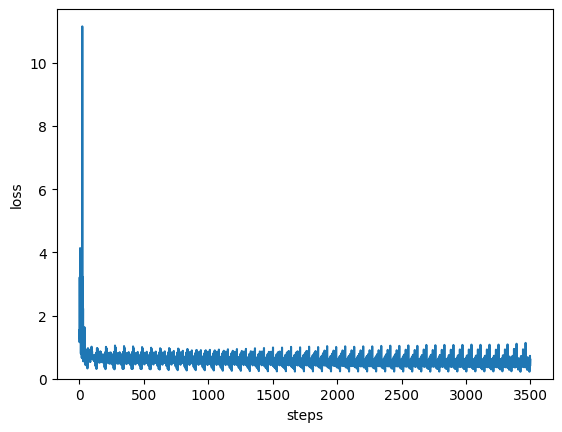

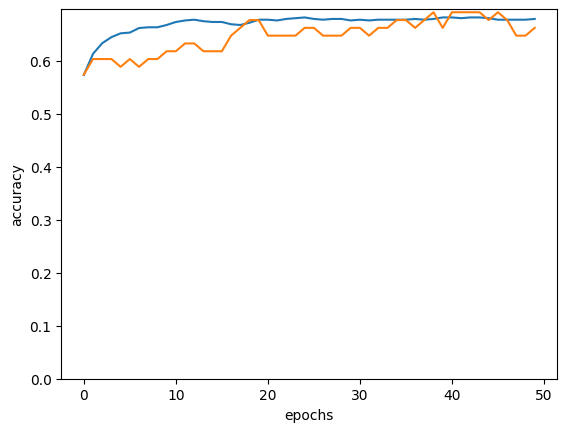

In [44]:
# load the dataset
dataset = np.loadtxt('pima-indians-diabetes.csv', delimiter=',')
X = dataset[:,0:8]
y = dataset[:,8]
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
# split the dataset into training and test sets
Xtrain = X[:700]
ytrain = y[:700]
Xtest = X[700:]
ytest = y[700:]
model = nn.Sequential(
nn.Linear(8, 12),
nn.ReLU(),
nn.Linear(12, 8),
nn.ReLU(),
nn.Linear(8, 1),
nn.Sigmoid()
)
print(model)
loss_fn = nn.BCELoss() # binary cross entropy
optimizer = optim.Adam(model.parameters(), lr=0.001)
n_epochs = 50 # number of epochs to run
batch_size = 10 # size of each batch
batches_per_epoch = len(Xtrain) // batch_size
# collect statistics
train_loss = []
train_acc = []
test_acc = []
for epoch in range(n_epochs):
        for i in range(batches_per_epoch):
# take a batch
                start = i * batch_size
                Xbatch = Xtrain[start:start+batch_size]
                ybatch = ytrain[start:start+batch_size]
# forward pass
                y_pred = model(Xbatch)
                loss = loss_fn(y_pred, ybatch)
                acc = (y_pred.round() == ybatch).float().mean()
# store metrics


                train_loss.append(float(loss))
                train_acc.append(float(acc))
# backward pass
                optimizer.zero_grad()
                loss.backward()
# update weights
                optimizer.step()
# print progress
                print(f"epoch {epoch} step {i} loss {loss} accuracy {acc}")
# evaluate model at end of epoch
        y_pred = model(Xtest)
        acc = (y_pred.round() == ytest).float().mean()
        test_acc.append(float(acc))
        print(f"End of {epoch}, accuracy {acc}")
# Plot the loss metrics
plt.plot(train_loss)
plt.xlabel("steps")
plt.ylabel("loss")
plt.ylim(0)
plt.show()

# plot the accuracy metrics
avg_train_acc = []
for i in range(n_epochs):
        start = i * batch_size
        average = sum(train_acc[start:start+batches_per_epoch]) / batches_per_epoch     
        avg_train_acc.append(average)
        
plt.plot(avg_train_acc, label="train")
plt.plot(test_acc, label="test")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0)
plt.show()

In [47]:
dataset = np.loadtxt('pima-indians-diabetes.csv', delimiter=',')
# split into input (X) and output (y) variables
X = dataset[:,0:8]
y = dataset[:,8]
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
# split the dataset into training and test sets
Xtrain = X[:700]
ytrain = y[:700]
Xtest = X[700:]
ytest = y[700:]
model = nn.Sequential(
nn.Linear(8, 12),
nn.ReLU(),
nn.Linear(12, 8),
nn.ReLU(),
nn.Linear(8, 1),
nn.Sigmoid()
)
print(model)
# loss function and optimizer
loss_fn = nn.BCELoss() # binary cross entropy
optimizer = optim.Adam(model.parameters(), lr=0.0001)
n_epochs = 50 # number of epochs to run
batch_size = 10 # size of each batch
batches_per_epoch = len(Xtrain) // batch_size
# collect statistics
train_loss = []
train_acc = []
test_acc = []
for epoch in range(n_epochs):
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
# take a batch
            start = i * batch_size
            Xbatch = Xtrain[start:start+batch_size]
            ybatch = ytrain[start:start+batch_size]
# forward pass
            y_pred = model(Xbatch)
            loss = loss_fn(y_pred, ybatch)
            acc = (y_pred.round() == ybatch).float().mean()
# store metrics
            train_loss.append(float(loss))
            train_acc.append(float(acc))
# backward pass
            optimizer.zero_grad()
            loss.backward()
# update weights
            optimizer.step()
# print progress
            bar.set_postfix(
                loss=float(loss),
                acc=f"{float(acc)*100:.2f}%"
)
# evaluate model at end of epoch
y_pred = model(Xtest)
acc = (y_pred.round() == ytest).float().mean()
test_acc.append(float(acc))
print(f"End of {epoch}, accuracy {acc}")

Sequential(
  (0): Linear(in_features=8, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


Epoch 0:   1%|▏         | 1/70 [00:00<00:00, 332.96batch/s, acc=60.00%, loss=0.747]

Epoch 49: 100%|██████████| 70/70 [00:00<00:00, 211.77batch/s, acc=40.00%, loss=0.756] 

End of 49, accuracy 0.6323529481887817


In [48]:
data = np.loadtxt("pima-indians-diabetes.csv", delimiter=",")
# find the boundary at 66% of total samples
count = len(data)
n_train = int(count * 0.66)
# split the data at the boundary
train_data = data[:n_train]
test_data = data[n_train:]

In [50]:
data = np.loadtxt("pima-indians-diabetes.csv", delimiter=",")
X = data[:, 0:8]
y = data[:, 8]
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

In [51]:
model = nn.Sequential(
nn.Linear(8, 12),
nn.ReLU(),
nn.Linear(12, 8),
nn.ReLU(),
nn.Linear(8, 1),
nn.Sigmoid()
)
# loss function and optimizer
loss_fn = nn.BCELoss() # binary cross-entropy
optimizer = optim.Adam(model.parameters(), lr=0.0001)
n_epochs = 50 # number of epochs to run
batch_size = 10 # size of each batch
batches_per_epoch = len(X_train) // batch_size


for epoch in range(n_epochs):
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
# take a batch
            start = i * batch_size
            X_batch = X_train[start:start+batch_size]
            y_batch = y_train[start:start+batch_size]
# forward pass
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
# backward pass
            optimizer.zero_grad()
            loss.backward()
# update weights
            optimizer.step()
# print progress
            bar.set_postfix(
                loss=float(loss)
)

Epoch 49: 100%|██████████| 51/51 [00:00<00:00, 217.57batch/s, loss=0.566]


In [55]:
for epoch in range(n_epochs):
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
# take a batch
            start = i * batch_size
            X_batch = X_train[start:start+batch_size]
            y_batch = y_train[start:start+batch_size]
# forward pass
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
# backward pass
            optimizer.zero_grad()
            loss.backward()
# update weights
            optimizer.step()

# print progress, with accuracy
            acc = (y_pred.round() == y_batch).float().mean()
            bar.set_postfix(
                loss=float(loss),
                acc=float(acc)
)

Epoch 49: 100%|██████████| 51/51 [00:00<00:00, 202.95batch/s, acc=0.7, loss=0.555]


In [56]:
for epoch in range(n_epochs):
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
# take a batch
            start = i * batch_size
            X_batch = X_train[start:start+batch_size]
            y_batch = y_train[start:start+batch_size]
# forward pass
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
# backward pass
            optimizer.zero_grad()
            loss.backward()
# update weights
            optimizer.step()
# print progress
            acc = (y_pred.round() == y_batch).float().mean()
            bar.set_postfix(
                loss=float(loss),
                acc=float(acc)
)
# evaluate model at end of epoch
y_pred = model(X_test)
acc = (y_pred.round() == y_test).float().mean()
acc = float(acc)
print(f"End of {epoch}, accuracy {acc}")

Epoch 49: 100%|██████████| 51/51 [00:00<00:00, 223.77batch/s, acc=0.7, loss=0.564]

End of 49, accuracy 0.6496062874794006


In [57]:
data = np.loadtxt("pima-indians-diabetes.csv", delimiter=",")
X = data[:, 0:8]
y = data[:, 8]
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)
model = nn.Sequential(
nn.Linear(8, 12),
nn.ReLU(),
nn.Linear(12, 8),
nn.ReLU(),
nn.Linear(8, 1),
nn.Sigmoid()
)
# loss function and optimizer
loss_fn = nn.BCELoss() # binary cross entropy
optimizer = optim.Adam(model.parameters(), lr=0.0001)
n_epochs = 50 # number of epochs to run
batch_size = 10 # size of each batch
batches_per_epoch = len(X_train) // batch_size
for epoch in range(n_epochs):
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
# take a batch
            start = i * batch_size
            X_batch = X_train[start:start+batch_size]
            y_batch = y_train[start:start+batch_size]
# forward pass
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
# backward pass
            optimizer.zero_grad()
            loss.backward()
# update weights
            optimizer.step()
# print progress
            acc = (y_pred.round() == y_batch).float().mean()
            bar.set_postfix(
                loss=float(loss),
                acc=float(acc)
)
# evaluate model at end of epoch
y_pred = model(X_test)
acc = (y_pred.round() == y_test).float().mean()
acc = float(acc)
print(f"End of {epoch}, accuracy {acc}")

Epoch 49: 100%|██████████| 51/51 [00:00<00:00, 327.52batch/s, acc=0.7, loss=0.549]

End of 49, accuracy 0.5984252095222473


In [62]:
def model_train(X_train, y_train, X_test, y_test):
# create new model
    model = nn.Sequential(
    nn.Linear(8, 12),
    nn.ReLU(),
    nn.Linear(12, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.Sigmoid())

y_pred = model(X_test)
acc = (y_pred.round() == y_test).float().mean()
def model_train(X_train, y_train, X_test, y_test):
    model = nn.Sequential(
        nn.Linear(8, 12),
        nn.ReLU(),
        nn.Linear(12, 8),
        nn.ReLU(),
        nn.Linear(8, 1),
        nn.Sigmoid()
    )

    loss_fn = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    n_epochs = 25
    batch_size = 10
    batches_per_epoch = len(X_train) // batch_size

    for epoch in range(n_epochs):
        with tqdm.trange(
            batches_per_epoch,
            unit="batch",
            mininterval=0,
            disable=True
        ) as bar:
            for i in bar:
                start = i * batch_size
                X_batch = X_train[start:start + batch_size]
                y_batch = y_train[start:start + batch_size]

                y_pred = model(X_batch)
                loss = loss_fn(y_pred, y_batch)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                acc = (y_pred.round() == y_batch).float().mean()
                bar.set_postfix(loss=float(loss), acc=float(acc))

    with torch.no_grad():
        y_pred = model(X_test)
        acc = (y_pred.round() == y_test).float().mean()

    return float(acc)


In [65]:
# define 5-fold cross-validation test harness
kfold = StratifiedKFold(n_splits=5, shuffle=True)
cv_scores = []
for train, test in kfold.split(X, y):
# create model, train, and get accuracy
    acc = model_train(X[train], y[train], X[test], y[test])
    print("Accuracy: %.2f" % acc)
    cv_scores.append(acc)
# evaluate the model
print("%.2f%% (+/- %.2f%%)" % (np.mean(cv_scores)*100, np.std(cv_scores)*100))

Accuracy: 0.64
Accuracy: 0.69
Accuracy: 0.65
Accuracy: 0.67
Accuracy: 0.62
65.23% (+/- 2.35%)


In [74]:
data = np.loadtxt("pima-indians-diabetes.csv", delimiter=",")
X = data[:, 0:8]
y = data[:, 8]
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
def model_train(X_train, y_train, X_test, y_test):
# create new model
    model = nn.Sequential(
    nn.Linear(8, 12),
    nn.ReLU(),
    nn.Linear(12, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.Sigmoid())

y_pred = model(X_test)
acc = (y_pred.round() == y_test).float().mean()
def model_train(X_train, y_train, X_test, y_test):
    model = nn.Sequential(
        nn.Linear(8, 12),
        nn.ReLU(),
        nn.Linear(12, 8),
        nn.ReLU(),
        nn.Linear(8, 1),
        nn.Sigmoid()
    )

    loss_fn = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    n_epochs = 25
    batch_size = 10
    batches_per_epoch = len(X_train) // batch_size

    for epoch in range(n_epochs):
        with tqdm.trange(
            batches_per_epoch,
            unit="batch",
            mininterval=0,
            disable=True
        ) as bar:
            for i in bar:
                start = i * batch_size
                X_batch = X_train[start:start + batch_size]
                y_batch = y_train[start:start + batch_size]

                y_pred = model(X_batch)
                loss = loss_fn(y_pred, y_batch)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                acc = (y_pred.round() == y_batch).float().mean()
                bar.set_postfix(loss=float(loss), acc=float(acc))

    with torch.no_grad():
        y_pred = model(X_test)
        acc = (y_pred.round() == y_test).float().mean()

    return float(acc)
kfold = StratifiedKFold(n_splits=5, shuffle=True)
cv_scores = []
for train, test in kfold.split(X, y):
# create model, train, and get accuracy
    acc = model_train(X[train], y[train], X[test], y[test])
    print("Accuracy: %.2f" % acc)
    cv_scores.append(acc)
# evaluate the model
print("%.2f%% (+/- %.2f%%)" % (np.mean(cv_scores)*100, np.std(cv_scores)*100))

Accuracy: 0.68
Accuracy: 0.65
Accuracy: 0.64
Accuracy: 0.59
Accuracy: 0.69
64.97% (+/- 3.52%)


In [75]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(y)
print(ohe.categories_)
y = ohe.transform(y)
print(y)

[array([0., 1.], dtype=float32)]
[[0. 1.]
 [1. 0.]
 [0. 1.]
 ...
 [1. 0.]
 [0. 1.]
 [1. 0.]]


Epoch 0: 100%|██████████| 21/21 [00:00<00:00, 251.37batch/s, acc=0.6, loss=1.05]


Epoch 0 validation: Cross-entropy=1.21, Accuracy=33.3%


Epoch 1: 100%|██████████| 21/21 [00:00<00:00, 188.80batch/s, acc=0.6, loss=1.03]


Epoch 1 validation: Cross-entropy=1.15, Accuracy=33.3%


Epoch 2: 100%|██████████| 21/21 [00:00<00:00, 233.33batch/s, acc=0.6, loss=1.02]


Epoch 2 validation: Cross-entropy=1.10, Accuracy=42.2%


... (390 outputs left out)

Epoch 198: 100%|██████████| 21/21 [00:00<00:00, 222.81batch/s, acc=1, loss=0.129]  


Epoch 198 validation: Cross-entropy=0.14, Accuracy=95.6%


Epoch 199: 100%|██████████| 21/21 [00:00<00:00, 250.38batch/s, acc=1, loss=0.129]  


Epoch 199 validation: Cross-entropy=0.14, Accuracy=95.6%


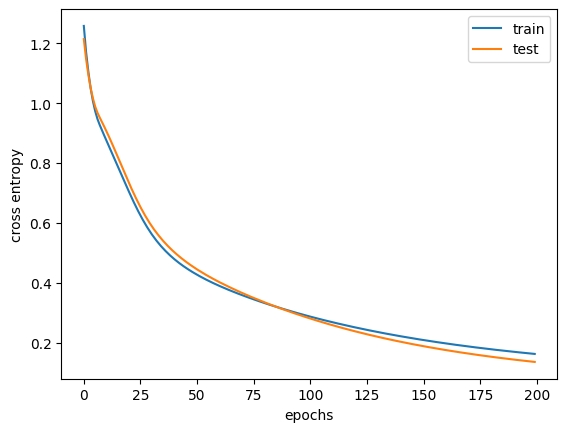

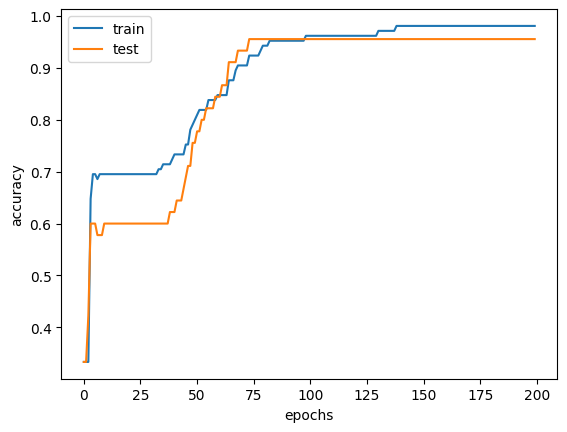

In [93]:
data = pd.read_csv("iris.csv", header=None)
X = data.iloc[:, 0:4]
y = data.iloc[:, 4:]
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(y)
y = ohe.transform(y)
# convert pandas DataFrame (X) and numpy array (y) into PyTorch tensors
X = torch.tensor(X.values, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)
# split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True)

class Multiclass(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(4, 8)
        self.act = nn.ReLU()
        self.output = nn.Linear(8, 3)

    def forward(self, x):
        x = self.act(self.hidden(x))
        x = self.output(x)
        return x

model = Multiclass()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
# prepare model and training parameters
n_epochs = 200
batch_size = 5
batches_per_epoch = len(X_train) // batch_size
best_acc = - np.inf # init to negative infinity
best_weights = None
train_loss_hist = []
train_acc_hist = []
test_loss_hist = []
test_acc_hist = []
# training loop
for epoch in range(n_epochs):
    epoch_loss = []
    epoch_acc = []
# set model in training mode and run through each batch


    model.train()
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
# take a batch
            start = i * batch_size
            X_batch = X_train[start:start+batch_size]
            y_batch = y_train[start:start+batch_size]
# forward pass
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
# backward pass
            optimizer.zero_grad()
            loss.backward()
# update weights
            optimizer.step()
# compute and store metrics
            acc = (torch.argmax(y_pred, 1) == torch.argmax(y_batch, 1)).float().mean()
            epoch_loss.append(float(loss))
            epoch_acc.append(float(acc))
            bar.set_postfix(
                loss=float(loss),
                acc=float(acc)
)
# set model in evaluation mode and run through the test set
    model.eval()
    y_pred = model(X_test)
    ce = loss_fn(y_pred, y_test)
    acc = (torch.argmax(y_pred, 1) == torch.argmax(y_test, 1)).float().mean()
    ce = float(ce)
    acc = float(acc)
    train_loss_hist.append(np.mean(epoch_loss))
    train_acc_hist.append(np.mean(epoch_acc))
    test_loss_hist.append(ce)
    test_acc_hist.append(acc)
    if acc > best_acc:
        best_acc = acc
        best_weights = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch} validation: Cross-entropy={ce:.2f}, Accuracy={acc*100:.1f}%")
# Restore best model
model.load_state_dict(best_weights)

# Plot the loss and accuracy
plt.plot(train_loss_hist, label="train")
plt.plot(test_loss_hist, label="test")
plt.xlabel("epochs")
plt.ylabel("cross entropy")
plt.legend()

plt.show()
plt.plot(train_acc_hist, label="train")
plt.plot(test_acc_hist, label="test")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.legend()
plt.show()

In [113]:
# Read data
data = pd.read_csv("sonar.csv", header=None)
X = data.iloc[:, 0:60]
y = data.iloc[:, 60]
encoder = LabelEncoder()
encoder.fit(y)
y = encoder.transform(y)
print(encoder.classes_)
print(y)

['M' 'R']
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [108]:
X = torch.tensor(X.values, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

In [109]:
class Wide(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(60, 180)
        self.relu = nn.ReLU()
        self.output = nn.Linear(180, 1)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        x = self.relu(self.hidden(x))
        x = self.sigmoid(self.output(x))
        return x

In [110]:
class Deep(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(60, 60)
        self.act1 = nn.ReLU()
        self.layer2 = nn.Linear(60, 60)
        self.act2 = nn.ReLU()
        self.layer3 = nn.Linear(60, 60)
        self.act3 = nn.ReLU()
        self.output = nn.Linear(60, 1)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        x = self.act1(self.layer1(x))
        x = self.act2(self.layer2(x))
        x = self.act3(self.layer3(x))
        x = self.sigmoid(self.output(x))
        return x

In [115]:
model1 = Wide()
model2 = Deep()
print(sum([x.reshape(-1).shape[0] for x in model1.parameters()])) # 11161
print(sum([x.reshape(-1).shape[0] for x in model2.parameters()])) # 11041

11161
11041


11161
11041
Accuracy (wide): 0.76
Accuracy (wide): 0.86
Accuracy (wide): 0.79
Accuracy (wide): 0.69
Accuracy (wide): 0.79
Accuracy (deep): 0.66
Accuracy (deep): 0.72
Accuracy (deep): 0.83
Accuracy (deep): 0.79
Accuracy (deep): 0.72
Wide: 77.93% (+/- 5.60%)
Deep: 74.48% (+/- 6.01%)
Retrain a wide model
Final model accuracy: 79.37%
[0.1371 0.1226 0.1385 0.1484 0.1776 0.1428 0.1773 0.2161 0.163  0.2067
 0.4257 0.5484 0.7131 0.7003 0.6777 0.7939 0.9382 0.8925 0.9146 0.7832
 0.796  0.7983 0.7716 0.6615 0.486  0.5572 0.4697 0.564  0.4517 0.3369
 0.2684 0.2339 0.3052 0.3016 0.2753 0.1041 0.1757 0.3156 0.3603 0.2736
 0.1301 0.2458 0.3404 0.1753 0.0679 0.1062 0.0643 0.0532 0.0531 0.0272
 0.0171 0.0118 0.0129 0.0344 0.0065 0.0067 0.0022 0.0079 0.0146 0.0051] -> [0.08788015] (expected [0.])
[0.0223 0.0375 0.0484 0.0475 0.0647 0.0591 0.0753 0.0098 0.0684 0.1487
 0.1156 0.1654 0.3833 0.3598 0.1713 0.1136 0.0349 0.3796 0.7401 0.9925
 0.9802 0.889  0.6712 0.4286 0.3374 0.7366 0.9611 0.7353 0.4856 0.1

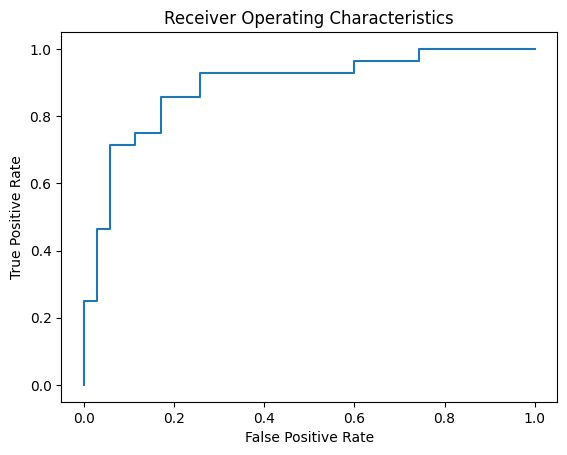

In [122]:
from sklearn.metrics import roc_curve


data = pd.read_csv("sonar.csv", header=None)
X = data.iloc[:, 0:60]
y = data.iloc[:, 60]
# Binary encoding of labels
encoder = LabelEncoder()
encoder.fit(y)
y = encoder.transform(y)
# Convert to 2D PyTorch tensors
X = torch.tensor(X.values, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
# Define two models
class Wide(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(60, 180)
        self.relu = nn.ReLU()
        self.output = nn.Linear(180, 1)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        x = self.relu(self.hidden(x))
        x = self.sigmoid(self.output(x))
        return x
class Deep(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(60, 60)
        self.act1 = nn.ReLU()
        self.layer2 = nn.Linear(60, 60)
        self.act2 = nn.ReLU()
        self.layer3 = nn.Linear(60, 60)
        self.act3 = nn.ReLU()
        self.output = nn.Linear(60, 1)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):

        x = self.act1(self.layer1(x))
        x = self.act2(self.layer2(x))
        x = self.act3(self.layer3(x))
        x = self.sigmoid(self.output(x))
        return x
# Compare model sizes
model1 = Wide()
model2 = Deep()
print(sum([x.reshape(-1).shape[0] for x in model1.parameters()])) # 11161
print(sum([x.reshape(-1).shape[0] for x in model2.parameters()])) # 11041
# Helper function to train one model
def model_train(model, X_train, y_train, X_val, y_val):
# loss function and optimizer
    loss_fn = nn.BCELoss() # binary cross entropy
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    n_epochs = 300 # number of epochs to run
    batch_size = 10 # size of each batch
    batch_start = torch.arange(0, len(X_train), batch_size)
# Hold the best model
    best_acc = - np.inf # init to negative infinity
    best_weights = None
    for epoch in range(n_epochs):
        model.train()
        with tqdm.tqdm(batch_start, unit="batch", mininterval=0, disable=True) as bar:
            bar.set_description(f"Epoch {epoch}")
            for start in bar:
# take a batch
                X_batch = X_train[start:start+batch_size]
                y_batch = y_train[start:start+batch_size]
# forward pass
                y_pred = model(X_batch)
                loss = loss_fn(y_pred, y_batch)
# backward pass
                optimizer.zero_grad()
                loss.backward()
# update weights
                optimizer.step()
# print progress
                acc = (y_pred.round() == y_batch).float().mean()
                bar.set_postfix(
                loss=float(loss),
                acc=float(acc)
)
# evaluate accuracy at end of each epoch
    model.eval()
    y_pred = model(X_val)
    acc = (y_pred.round() == y_val).float().mean()
    acc = float(acc)
    if acc > best_acc:
        best_acc = acc
        best_weights = copy.deepcopy(model.state_dict())
# restore model and return best accuracy
    model.load_state_dict(best_weights)
    return best_acc
# train-test split: Hold out the test set for final model evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True)
# define 5-fold cross validation test harness
kfold = StratifiedKFold(n_splits=5, shuffle=True)
cv_scores_wide = []
for train, test in kfold.split(X_train, y_train):
# create model, train, and get accuracy
    model = Wide()
    acc = model_train(model, X_train[train], y_train[train], X_train[test], y_train[test])
    print("Accuracy (wide): %.2f" % acc)
    cv_scores_wide.append(acc)
cv_scores_deep = []
for train, test in kfold.split(X_train, y_train):
# create model, train, and get accuracy
    model = Deep()
    acc = model_train(model, X_train[train], y_train[train], X_train[test], y_train[test])
    print("Accuracy (deep): %.2f" % acc)
    cv_scores_deep.append(acc)
# evaluate the model
wide_acc = np.mean(cv_scores_wide)
wide_std = np.std(cv_scores_wide)
deep_acc = np.mean(cv_scores_deep)
deep_std = np.std(cv_scores_deep)
print("Wide: %.2f%% (+/- %.2f%%)" % (wide_acc*100, wide_std*100))
print("Deep: %.2f%% (+/- %.2f%%)" % (deep_acc*100, deep_std*100))
# rebuild model with full set of training data
if wide_acc > deep_acc:
    print("Retrain a wide model")
    model = Wide()
else:
    print("Retrain a deep model")
    model = Deep()
acc = model_train(model, X_train, y_train, X_test, y_test)
print(f"Final model accuracy: {acc*100:.2f}%")
model.eval()
with torch.no_grad():
# Test out inference with 5 samples
    for i in range(5):
        y_pred = model(X_test[i:i+1])
        print(f"{X_test[i].numpy()} -> {y_pred[0].numpy()} " +
        f"(expected {y_test[i].numpy()})")

# Plot the ROC curve
    y_pred = model(X_test).detach().cpu().numpy().ravel()
    y_true = y_test.detach().cpu().numpy().ravel()
    fpr, tpr, thresholds = roc_curve(y_test, y_pred)    
    plt.plot(fpr, tpr) # ROC curve = TPR vs FPR
    plt.title("Receiver Operating Characteristics") 
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.show()